In [95]:
# INSTALL IF NECESSARY

%pip install pandas numpy pillow matplotlib tensorflow scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [96]:
# -*- coding: utf-8 -*-

**AER850 Project Phase II: Data Preprocessing**


Mars Surface / Curiosity image set (Kaggle)

In [97]:
# SETUP
from pathlib import Path
import json  
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageOps
from IPython.display import display
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd()  # finds current directory
DATA_DIR = PROJECT_ROOT / "Data" / "Mars_Surface_and_Curiosity_Image"
IMAGE_DIR = DATA_DIR / "images"  # complete image collection location
OUT_DIR = PROJECT_ROOT / "processed"  # output will be saved here

# every image gets resized to IMG_SIZE x IMG_SIZE
IMG_SIZE = 224

BATCH_SIZE = 16  # process a few images at a time; can lower this if memory is limited
SEED = 42   # allows for reproducibility of random operations

# error messages for missing directories
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Missing images folder: {IMAGE_DIR}")
OUT_DIR.mkdir(exist_ok=True)

# check that directories are correct
print("Project:", PROJECT_ROOT)
print("Dataset:", DATA_DIR)
print("Generated files:", OUT_DIR)

Project: c:\Users\linda\Documents\GitHub\AER850_Phase2
Dataset: c:\Users\linda\Documents\GitHub\AER850_Phase2\Data\Mars_Surface_and_Curiosity_Image
Generated files: c:\Users\linda\Documents\GitHub\AER850_Phase2\processed


Files are split into training, validation, and test based on the .csv's that are included with the dataset.


In [98]:
# load the CSV's

split_files = { 
    "train": "Train_CSV.csv",
    "validation": "Validation_CSV.csv",
    "test": "Test_CSV.csv",
}

tables = []  # empty list that will hold three tables
for split, filename in split_files.items():
    table = pd.read_csv(DATA_DIR / filename, dtype={"JPG": "string", "LABELS": "Int64"})
    table = table.rename(columns={"JPG": "file", "LABELS": "label"})
    table["split"] = split  # add the split name to every row in this table
    tables.append(table)  # add this table to the list
df = pd.concat(tables, ignore_index=True)  # stack the tables and number rows from zero
display(df.head(10))  # show the first ten rows
display(df["split"].value_counts())  # count rows in each split

,file,label,split
0,calibrated/0077ML0005780000102730I01_DRCL.JPG,15,train
1,calibrated/0072MR0005610170103642E01_DRCL.JPG,8,train
2,calibrated/0069MR0004130000103477I01_DRCL.JPG,21,train
3,calibrated/0154ML0008510010104492E01_DRCL.JPG,8,train
4,calibrated/0019MR0000530000100138C00_DRCL.JPG,8,train
5,calibrated/0017ML0000500200100233B00_DRCL.JPG,8,train
6,calibrated/0025MR0001230130100711E01_DRCL.JPG,8,train
7,calibrated/0044MR0002011110102490E01_DRCL.JPG,8,train
8,calibrated/0003ML0000000160100036I01_DRCL.JPG,9,train
9,calibrated/0159MR0008640180201373E01_DRCL.JPG,8,train


split
train         3746
validation    1640
test          1305
Name: count, dtype: int64

The dataset is encoded using integer labels; each image category has a number defined in Labels Information.txt.

The labels are defined as shown below:

| ID | Target / Feature | ID | Target / Feature | ID | Target / Feature |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **0** | apxs | **9** | horizon | **18** | portion tube opening |
| **1** | apxs cal target | **10** | inlet | **19** | rems uv sensor |
| **2** | chemcam cal target | **11** | mahli | **20** | rover rear deck |
| **3** | chemin inlet open | **12** | mahli cal target | **21** | scoop |
| **4** | drill | **13** | mastcam | **22** | sun |
| **5** | drill holes | **14** | mastcam cal target | **23** | turret |
| **6** | drt front | **15** | observation tray | **24** | wheel |
| **7** | drt side | **16** | portion box | | |
| **8** | ground | **17** | portion tube | | |


**Notes**: Sun (22) has no examples anywhere, several classes are absent from validation or test, and class proportions differ substantially between splits.


For this reason, new stratified splits will be created. 70% will be used to train, and the remaining 30% is split evenly between validation and test sets. The combined data from all 3 CSV's will be used for this, so that the labels stay attached to their respective images.

In [99]:
# keep original assignment for comparison
original_df = df.copy()

# 70% training
new_train, held_out = train_test_split(
    original_df,
    test_size=0.30,
    stratify=original_df["label"],
    random_state=SEED
)

# 15% validation, 15% test
new_validation, new_test = train_test_split(
    held_out,
    test_size=0.50,
    stratify=held_out["label"],
    random_state=SEED
)

# record new assignments without modifying original CSVs
new_train = new_train.assign(split="train")
new_validation = new_validation.assign(split="validation")
new_test = new_test.assign(split="test")

df = pd.concat(
    [new_train, new_validation, new_test],
    ignore_index=True
)

display(df.head(10))  # show the first ten rows
display(df["split"].value_counts())  # count rows in each split

,file,label,split
0,calibrated/0017MR0000510100100116C00_DRCL.JPG,8,train
1,calibrated/0270MH0002530050102770I01_DRCL.JPG,5,train
2,calibrated/0078MR0005860030103921E01_DRCL.JPG,8,train
3,calibrated/0128ML0007340000103941E01_DRCL.JPG,21,train
4,calibrated/0157ML0008550030104532I01_DRCL.JPG,8,train
5,calibrated/0283MH0002730050103231I01_DRCL.JPG,5,train
6,calibrated/0085MH0001130000100953I01_DRCL.JPG,9,train
7,calibrated/0003ML0000000490100069I01_DRCL.JPG,8,train
8,calibrated/0548MH0002600000201531E01_DRCL.JPG,24,train
9,calibrated/0013ML0000150050100188I01_DRCL.JPG,9,train


split
train         4683
validation    1004
test          1004
Name: count, dtype: int64

Comparison of label percentages in train, validation, and data splits.

In [100]:
id_to_name = {}  # maps numeric ID to class name
with (DATA_DIR / "Labels Information.txt").open(encoding="utf-8-sig") as handle:
    for line in handle:
        if line.strip():
            label_id, class_name = line.strip().split(maxsplit=1)
            id_to_name[int(label_id)] = class_name

def summarize_labels(data):
    # count each label in each set
    counts = pd.crosstab(data["label"], data["split"])

    # include all defined labels, even those with 0 images
    counts = counts.reindex(
        index=sorted(id_to_name),
        columns=["train", "validation", "test"],
        fill_value=0
    )

    # summary table with class names
    summary = pd.DataFrame(index=counts.index)
    summary["class_name"] = summary.index.map(id_to_name)

    # add count and percentage for each set
    for split in ["train", "validation", "test"]:
        summary[f"{split}_count"] = counts[split]

        summary[f"{split}_percent"] = (
            100 * counts[split] / counts[split].sum()
        ).round(2)

    return summary.rename_axis("label").reset_index()


# create both summaries (ogirinal & resplit)
original_summary = summarize_labels(original_df)
new_summary = summarize_labels(df)

# display both tables
print("ORIGINAL SPLITS — percentages within each set")
display(original_summary)
print("NEW STRATIFIED SPLITS — percentages within each set")
display(new_summary)

# combine both summaries into one CSV
original_summary.insert(0, "split_strategy", "original")
new_summary.insert(0, "split_strategy", "stratified")
comparison = pd.concat(
    [original_summary, new_summary],
    ignore_index=True
)

OUT_DIR.mkdir(exist_ok=True)
output_path = OUT_DIR / "original_vs_stratified_class_percentages.csv"
comparison.to_csv(output_path, index=False)

print("Saved to:", output_path)

ORIGINAL SPLITS — percentages within each set


,label,class_name,train_count,train_percent,validation_count,validation_percent,test_count,test_percent
0,0,apxs,30,0.80,16,0.98,34,2.61
1,1,apxs cal target,6,0.16,4,0.24,14,1.07
2,2,chemcam cal target,15,0.40,0,0.00,21,1.61
3,3,chemin inlet open,47,1.25,45,2.74,84,6.44
4,4,drill,19,0.51,20,1.22,20,1.53
5,5,drill holes,36,0.96,470,28.66,0,0.00
6,6,drt front,4,0.11,2,0.12,60,4.60
7,7,drt side,8,0.21,4,0.24,150,11.49
8,8,ground,2343,62.55,87,5.30,254,19.46
9,9,horizon,224,5.98,75,4.57,72,5.52


NEW STRATIFIED SPLITS — percentages within each set


,label,class_name,train_count,train_percent,validation_count,validation_percent,test_count,test_percent
0,0,apxs,56,1.20,12,1.20,12,1.20
1,1,apxs cal target,17,0.36,4,0.40,3,0.30
2,2,chemcam cal target,25,0.53,5,0.50,6,0.60
3,3,chemin inlet open,123,2.63,27,2.69,26,2.59
4,4,drill,41,0.88,9,0.90,9,0.90
5,5,drill holes,354,7.56,76,7.57,76,7.57
6,6,drt front,46,0.98,10,1.00,10,1.00
7,7,drt side,113,2.41,24,2.39,25,2.49
8,8,ground,1879,40.12,402,40.04,403,40.14
9,9,horizon,260,5.55,56,5.58,55,5.48


Saved to: c:\Users\linda\Documents\GitHub\AER850_Phase2\processed\original_vs_stratified_class_percentages.csv


Check for repeated filenames between splits (this does not detect duplicate image content, mislabeled visual content or similar issues, which require additional inspection).

**There are 6691 image files across all splits.**

In [101]:
df["filename"] = df["file"].str.replace("\\", "/", regex=False).str.rsplit("/", n=1).str[-1]
duplicates = df[df["filename"].duplicated(keep=False)]
if not duplicates.empty:
    display(duplicates.sort_values("filename"))
    raise ValueError("Repeated filename found. Investigate within-split duplicates and split overlap.")
print("Unique filenames:", df["filename"].nunique())
print("No filename overlap between the supplied splits.")


Unique filenames: 6691
No filename overlap between the supplied splits.


Check to see whether any image files have errors, with the list based on the provided split CSV's.

The audit checks:
- Does the image file exist?
- Can Python open and read its pixels?
- What are its width and height?
- Is it grayscale (L) or colour (RGB)?

Outputs a CSV; any flagged errors should be checked and any issues resolved before running feature extraction.

In [102]:
checks = []

for reference in df["file"]:
    path = IMAGE_DIR / Path(reference.replace("\\", "/")).name

    result = {
        "image_relpath": "",
        "width": None,
        "height": None,
        "mode": "",
        "error": ""
    }

    try:
        with Image.open(path) as im:
            im.load()
            result.update(
                image_relpath=path.relative_to(PROJECT_ROOT).as_posix(),
                width=im.width,
                height=im.height,
                mode=im.mode
            )
    except (OSError, ValueError) as error:
        result["error"] = str(error)

    checks.append(result)

# replaces previous results so this cell can be rerun
audit = pd.DataFrame(checks, index=df.index)
df = df.drop(columns=audit.columns, errors="ignore")
df[audit.columns] = audit

# save the CSV and print the number of problems
df.to_csv(OUT_DIR / "image_audit.csv", index=False)
problem_count = (df["error"] != "").sum()
print(f"Image checks complete: {problem_count} problems found. Saved image_audit.csv.")

Image checks complete: 0 problems found. Saved image_audit.csv.


Based on the CSV generated from the above cell, the images have multiple different dimensions. The image size must be standardized across the entire dataset.

- The dataset contains both RGB and B&W (L) images; all images will be converted to RGB.
- Because the image will be changed into 8-bit RGB, all values will be in a range of 0-255.

`load_pixels` prepares the image:
- Makes it three-channel RGB. Each pixel has red, green, and blue values, and a grayscale image gets its brightness copied into all three channels.
- Makes it 224 × 224 pixels. Resizes without stretching the scene (to avoid distortion of image elements), then adds black borders where needed (padding).
- Turns it into numbers. The result has the shape (224, 224, 3): height, width, & 3 colour channels.
- Uses floating-point numbers. float32 allows calculations with decimals. Changing 120 to 120.0 does not change the brightness or scale (values are still between 0 and 255).

All of the processed images are saved into processed/images

In [103]:
def load_pixels(relative_path):
    with Image.open(PROJECT_ROOT / relative_path) as im:
        # convert colour & grayscale images to 3-channel RGB.
        rgb = im.convert("RGB")

        # resize without stretching, adding black padding if needed
        resized = ImageOps.pad(
            rgb,
            (IMG_SIZE, IMG_SIZE),
            method=Image.Resampling.BILINEAR,
            color=(0, 0, 0)
        )

        # return floating-point pixels with values 0–255
        return np.asarray(resized, dtype=np.float32)


# create folder for processed images
processed_image_dir = OUT_DIR / "images"
processed_image_dir.mkdir(parents=True, exist_ok=True)

processed_paths = []

for relative_path in df["image_relpath"]:
    pixels = load_pixels(relative_path)

    # save a resized RGB copy as an 8-bit PNG
    output_path = processed_image_dir / (
        Path(relative_path).stem + ".png"
    )
    Image.fromarray(pixels.astype(np.uint8)).save(output_path)

    # record its location relative to the project root folder
    processed_paths.append(
        output_path.relative_to(PROJECT_ROOT).as_posix()
    )

df["processed_image_relpath"] = processed_paths
df.to_csv(OUT_DIR / "processed_image_data.csv", index=False)

print(f"Saved {len(processed_paths)} processed images.")

Saved 6691 processed images.


Images must be prepared for ResNet50:
- Change the channel order from red, green, blue to blue, green, red.
- Subtract a fixed average value from each channel, based on the ImageNet images used to train the model.

In [104]:
from tensorflow.keras.applications.resnet50 import preprocess_input

def load_resnet_batch(relative_paths):
    images = []

    for relative_path in relative_paths:
        with Image.open(PROJECT_ROOT / relative_path) as im:
            pixels = np.asarray(im.convert("RGB"), dtype=np.float32)
            images.append(pixels)

    # combine images into one batch
    batch = np.stack(images)

    # change RGB to BGR and subtract the ImageNet channel averages
    return preprocess_input(batch)

Load ResNet50 for **feature extraction**

Essentially, the purpose of ResNet50 is to identify features in the images, completely independent of any labels related to the Mars images: Mars image > Already-trained ResNet50 (on ImageNet) (weights stay fixed) > 2,048 extracted features > Random forest learns from features & training labels > Select important feature columns

- `weights="imagenet"` loads the pre-learned weights from ImageNet.
- `include_top=False` removes ResNet50’s original classifier for ImageNet’s 1,000 categories, keeping the feature-extraction layers but making it so that ResNet won't output final classifications like "dog" or "tree".
- `trainable=False` keeps the pretrained weights fixed (we aren't training ResNet50).

ResNet has a prespecified internal structure, so this is the dimension-change process from the original 224 × 224 image (there's more operations in between size changes which can be seen with `extractor.summary()` but this is what changes the dimensions):
1. 224 × 224   Input image
2. 112 × 112   First convolution, stride 2
3. 56 × 56    Max pooling, stride 2
4. 28 × 28    Later convolutional stage
5. 14 × 14    Later convolutional stage
6. 7 × 7     Final convolutional stage

The final convolutional output contains 2,048 feature maps, each size 7 × 7. `pooling="avg"` applies global average pooling: it averages the 49 values in each feature map into one number.

The result is **2,048 feature values per image**. For a batch of images, the output shape is (batch_size, 2048).

In [105]:
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import ResNet50

tf.keras.utils.set_random_seed(SEED)

extractor = ResNet50(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

extractor.trainable = False

print("Features per image:", extractor.output_shape[-1])

Features per image: 2048


Run images through ResNet50 and collect 2,048 features for each image, keeping training, validation, and test separate.

In [106]:
def extract_features(table):
    batch_results = []
    for start in range(0, len(table), BATCH_SIZE):
        paths = table.iloc[start:start + BATCH_SIZE]["processed_image_relpath"]
        prepared = load_resnet_batch(paths)
        batch_features = extractor.predict(prepared, verbose=0)
        batch_results.append(batch_features)
        print("Extracted", min(start + BATCH_SIZE, len(table)), "of", len(table))
    result = np.concatenate(batch_results, axis=0).astype(np.float32)
    if result.shape != (len(table), 2048) or not np.isfinite(result).all():
        raise ValueError("Unexpected feature shape or non-finite values.")
    return result

split_tables = {}
features = {}
for split in split_files:
    split_tables[split] = df[df["split"] == split].reset_index(drop=True)
    if split_tables[split].empty:
        raise ValueError(f"The {split} split is empty.")
    print("Processing split:", split)
    features[split] = extract_features(split_tables[split])
    print("Feature shape:", features[split].shape)


Processing split: train
Extracted 16 of 4683
Extracted 32 of 4683
Extracted 48 of 4683
Extracted 64 of 4683
Extracted 80 of 4683
Extracted 96 of 4683
Extracted 112 of 4683
Extracted 128 of 4683
Extracted 144 of 4683
Extracted 160 of 4683
Extracted 176 of 4683
Extracted 192 of 4683
Extracted 208 of 4683
Extracted 224 of 4683
Extracted 240 of 4683
Extracted 256 of 4683
Extracted 272 of 4683
Extracted 288 of 4683
Extracted 304 of 4683
Extracted 320 of 4683
Extracted 336 of 4683
Extracted 352 of 4683
Extracted 368 of 4683
Extracted 384 of 4683
Extracted 400 of 4683
Extracted 416 of 4683
Extracted 432 of 4683
Extracted 448 of 4683
Extracted 464 of 4683
Extracted 480 of 4683
Extracted 496 of 4683
Extracted 512 of 4683
Extracted 528 of 4683
Extracted 544 of 4683
Extracted 560 of 4683
Extracted 576 of 4683
Extracted 592 of 4683
Extracted 608 of 4683
Extracted 624 of 4683
Extracted 640 of 4683
Extracted 656 of 4683
Extracted 672 of 4683
Extracted 688 of 4683
Extracted 704 of 4683
Extracted 720 

Visualization of feature maps in ResNet50 before the final average-pooling layer.

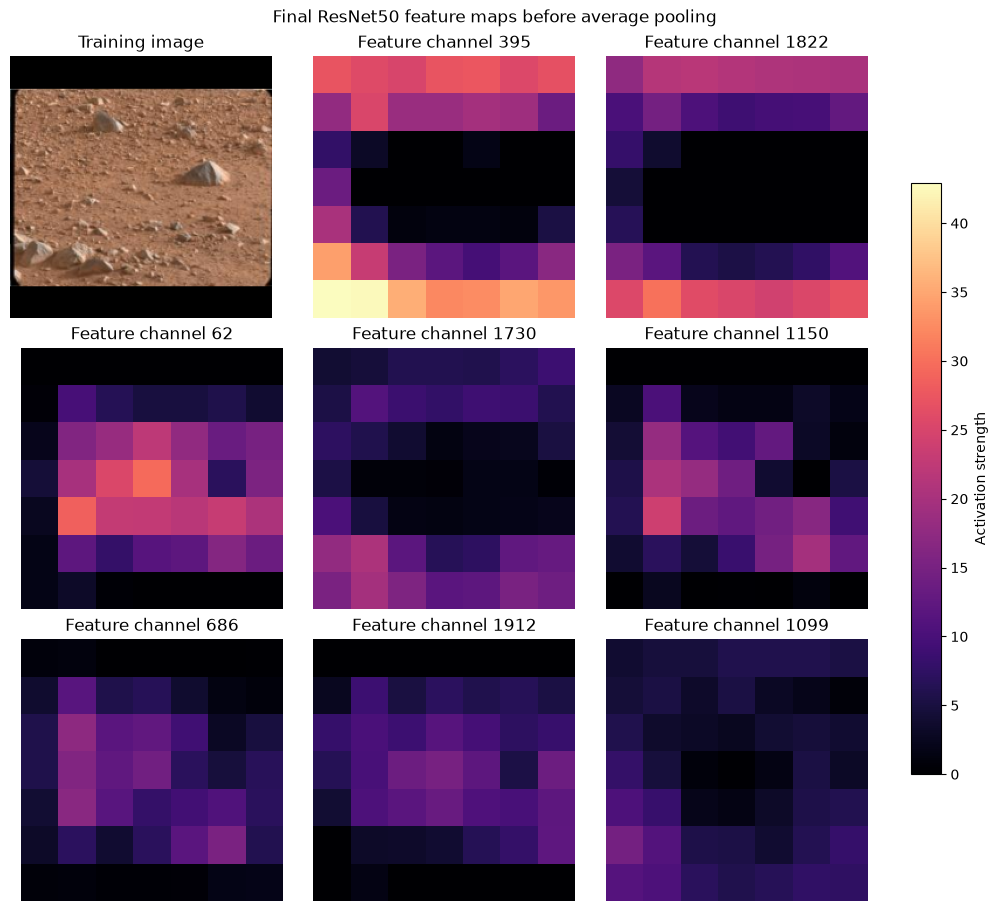

Map array shape: (7, 7, 2048)
Saved: c:\Users\linda\Documents\GitHub\AER850_Phase2\processed\feature_maps.png


In [107]:
# return feature maps before the final average-pooling layer
map_extractor = tf.keras.Model(
    inputs=extractor.input,
    outputs=extractor.get_layer("conv5_block3_out").output
)
map_extractor.trainable = False

# choose one training image
example = df[df["split"] == "train"].iloc[0]
path_column = "processed_image_relpath" if "processed_image_relpath" in df.columns else "image_relpath"
with Image.open(PROJECT_ROOT / example[path_column]) as im:
    image = ImageOps.pad(
        im.convert("RGB"), (IMG_SIZE, IMG_SIZE),
        method=Image.Resampling.BILINEAR, color=(0, 0, 0)
    )
    display_pixels = np.asarray(image).copy()

# prepare this image exactly once, then obtain its maps
batch = display_pixels.astype(np.float32)[None, ...]
prepared = preprocess_input(batch)
maps = map_extractor.predict(prepared, verbose=0)[0]

# show the eight channels with the largest average response for this image
channel_scores = maps.mean(axis=(0, 1))
channels = np.argsort(channel_scores)[-8:][::-1]
color_max = max(float(maps.max()), 1e-8)

fig, axes = plt.subplots(3, 3, figsize=(10, 9), layout="constrained")
axes = axes.ravel()
axes[0].imshow(display_pixels)
axes[0].set_title("Training image")
axes[0].axis("off")
for axis, channel in zip(axes[1:], channels):
    heatmap = axis.imshow(maps[:, :, channel], cmap="magma",
                          vmin=0, vmax=color_max, interpolation="nearest")
    axis.set_title(f"Feature channel {channel}")
    axis.axis("off")
fig.colorbar(heatmap, ax=list(axes[1:]), shrink=0.7, label="Activation strength")
fig.suptitle("Final ResNet50 feature maps before average pooling")
OUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / "feature_maps.png", dpi=180)
plt.show()
print("Map array shape:", maps.shape)
print("Saved:", OUT_DIR / "feature_maps.png")


Create a PCA plot for visualization: summarizes the extracted image features using two principal components, PC1 and PC2. Each dot represents one training image and is coloured according to its class label. The labels are used only for colouring the dots, not for calculating their positions.

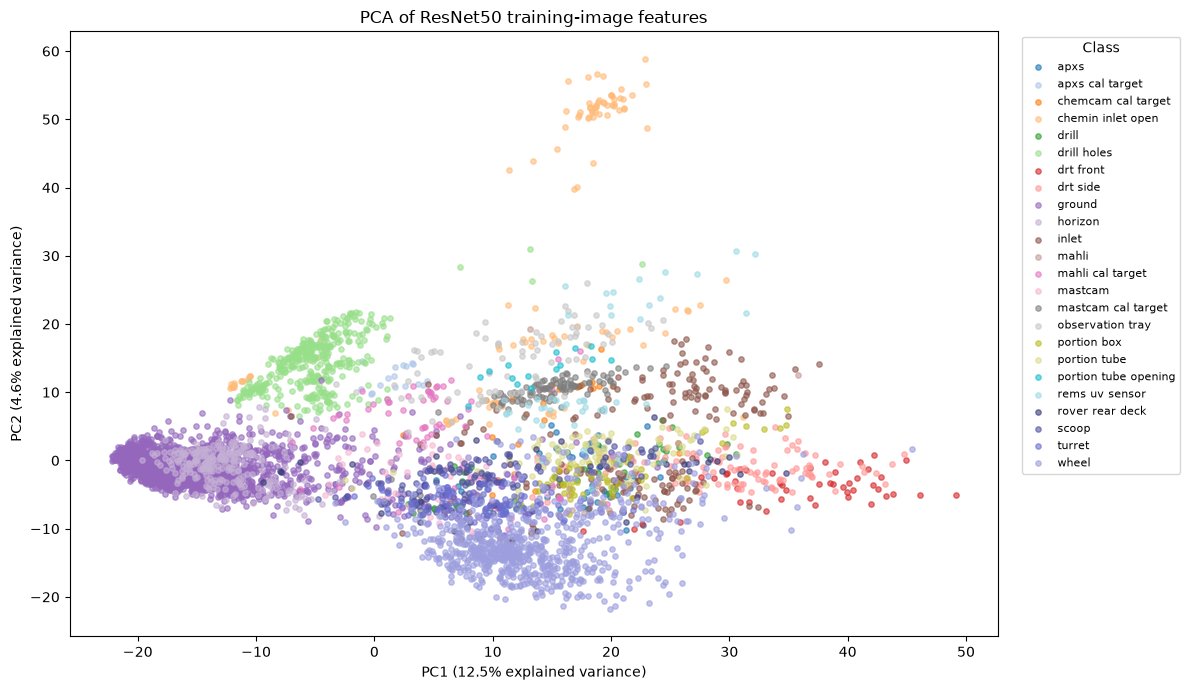

In [108]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# scale the training features before calculating PCA
pca_scaler = StandardScaler()
pca_input = pca_scaler.fit_transform(features["train"])

# calculate two principal components using training data only
plot_pca = PCA(n_components=2, svd_solver="full")
coordinates = plot_pca.fit_transform(pca_input)

# get matching labels
labels = split_tables["train"]["label"].to_numpy()
class_ids = np.unique(labels)

# colours for the observed classes
colours = (
    list(plt.get_cmap("tab20").colors)
    + list(plt.get_cmap("tab20b").colors)
)

fig, ax = plt.subplots(figsize=(12, 7))

for colour, label_id in zip(colours, class_ids):
    mask = labels == label_id

    ax.scatter(
        coordinates[mask, 0],
        coordinates[mask, 1],
        color=colour,
        label=id_to_name[label_id],
        s=15,
        alpha=0.6
    )

# show how much variation each axis represents
variance = plot_pca.explained_variance_ratio_ * 100

ax.set_xlabel(f"PC1 ({variance[0]:.1f}% explained variance)")
ax.set_ylabel(f"PC2 ({variance[1]:.1f}% explained variance)")
ax.set_title("PCA of ResNet50 training-image features")

ax.legend(
    title="Class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

fig.tight_layout()
fig.savefig(OUT_DIR / "pca_training_plot.png", dpi=180, bbox_inches="tight")
plt.show()

**Feature extraction** is necessary to decide which of ResNet's 2048 features are actually helpful for distinguishing the Mars image classes, so that only the valuable ones are retained.

This will be done using a Random Forest; the model is trained to learn relationships between the 2048 extracted features and the training labels, then assigns importance scores to those feature columns.

| Setting | What does it do |
|---|---|
| `n_estimators=100` | Use 100 decision trees |
| `max_depth=12` | Limit how many decision levels each tree can have |
| `class_weight="balanced_subsample"` | Give rarer classes more weight within each tree’s training sample |
| `random_state=SEED` | Make its random choices reproducible |
| `n_jobs=-1` | Use available CPU cores |

In [109]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

y_train = split_tables["train"]["label"].to_numpy(dtype=np.int64)
if np.unique(y_train).size < 2:
    raise ValueError("Feature selection requires at least two observed training classes.")
forest = RandomForestClassifier(n_estimators=100, max_depth=12,
                                class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
selector = SelectFromModel(forest, threshold="mean")
selector.fit(features["train"], y_train)  
forest = selector.estimator_ 
if not np.isfinite(forest.feature_importances_).all() or forest.feature_importances_.sum() <= 0:
    raise ValueError("No useful training feature importance was learned; investigate the inputs.")
selected_indices = selector.get_support(indices=True)
if selected_indices.size == 0:
    raise ValueError("No features were selected.")
selected_features = {}
for split in split_files:
    selected_features[split] = selector.transform(features[split]).astype(np.float32)
print("Original features:", features["train"].shape[1])
print("Selected features:", selected_indices.size)
print("Selection threshold:", selector.threshold_)

Original features: 2048
Selected features: 592
Selection threshold: 0.00048828125


Save and plot the feature ranking:

,feature_index,importance,selected
1650,1650,0.007858,True
173,173,0.007229,True
1151,1151,0.006898,True
1555,1555,0.006207,True
1622,1622,0.005886,True
1137,1137,0.005654,True
1810,1810,0.005623,True
1142,1142,0.005610,True
848,848,0.004932,True
1037,1037,0.004806,True


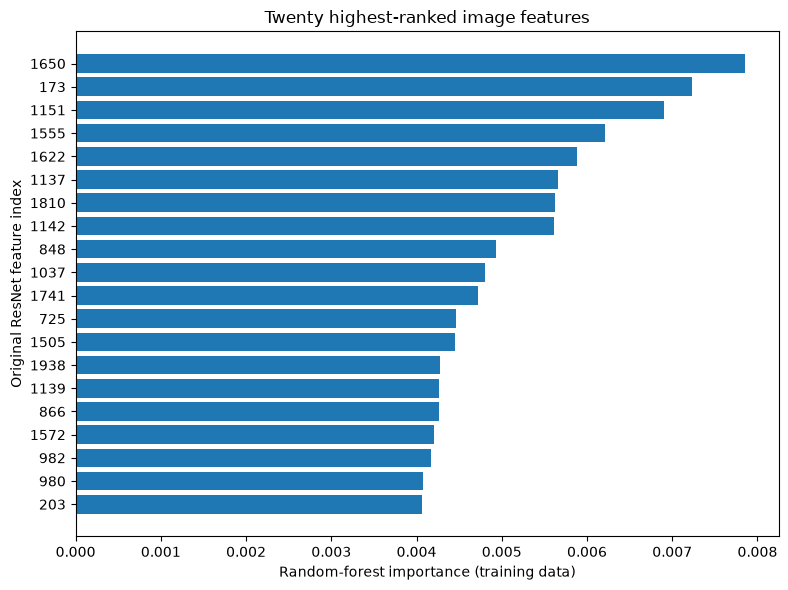

In [110]:
importance_table = pd.DataFrame({
    "feature_index": np.arange(features["train"].shape[1]),
    "importance": forest.feature_importances_,
    "selected": np.isin(np.arange(features["train"].shape[1]), selected_indices),
}).sort_values("importance", ascending=False)
importance_table.to_csv(OUT_DIR / "feature_importance.csv", index=False)
display(importance_table.head(20))
top_features = importance_table.head(20).sort_values("importance")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_features["feature_index"].astype(str), top_features["importance"])
ax.set_xlabel("Random-forest importance (training data)")
ax.set_ylabel("Original ResNet feature index")
ax.set_title("Twenty highest-ranked image features")
plt.tight_layout()
plt.savefig(OUT_DIR / "feature_importance.png", dpi=160)
plt.show()

Standardize the Selected Features

- Makes the selected feature values use comparable scales.
- Learns each feature’s average and spread from training data only.
- Applies the same adjustment to all sets: average training values become 0, lower values become negative, and higher values become positive.
- Saves a CSV comparing each feature’s average and spread before and after scaling.

In [111]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(selected_features["train"])  # learn scaling from training rows only.
processed_features = {}
for split in split_files:
    processed_features[split] = scaler.transform(selected_features[split]).astype(np.float32)
    if not np.isfinite(processed_features[split]).all():
        raise ValueError(f"Non-finite scaled features in {split}.")
scaling_summary = pd.DataFrame({
    "feature_index": selected_indices,
    "training_mean_before": selected_features["train"].mean(axis=0),
    "training_std_before": selected_features["train"].std(axis=0),
    "training_mean_after": processed_features["train"].mean(axis=0),
    "training_std_after": processed_features["train"].std(axis=0),
})
scaling_summary.to_csv(OUT_DIR / "scaling_summary.csv", index=False)
display(scaling_summary.head(10))

,feature_index,training_mean_before,training_std_before,training_mean_after,training_std_after
0,4,0.387487,0.505185,-1.303335e-08,1.0
1,7,0.174909,0.243878,8.145841e-10,1.0
2,9,1.083443,1.373319,1.873543e-08,1.0
3,11,0.134287,0.244018,-1.751356e-08,1.0
4,13,0.183645,0.369960,-8.960425e-09,1.0
5,19,0.283745,0.626627,-6.923965e-09,1.0
6,22,0.320884,0.600174,-8.145840e-09,1.0
7,27,0.217037,0.345582,-4.072920e-09,1.0
8,34,0.200860,0.414201,4.887505e-09,1.0
9,35,0.451664,0.814027,-4.072920e-10,1.0
